# 07 - Model Comparison

Every stage side by side. This notebook only *reads*: each model notebook
writes its 5-fold result to `results.csv` (summary) and `results_folds.csv`
(per fold) when run. Run `02`-`06` first.

**Shared protocol, so the rows are comparable.** Same preprocessing (`01`),
same five subject-grouped folds, same scoring: one decision per subject by
averaging that person's epoch probabilities, mean +- SD across folds.

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#8a8a85"
ORDER = ["Logistic Regression", "LogReg + PCA", "Random Forest", "XGBoost", "CNN-LSTM"]
NOTEBOOK = dict(zip(ORDER, ["02_Logistic_Regression", "03_Logistic_Regression_PCA",
                            "04_Random_Forest", "05_XGBoost", "06_CNN_LSTM"]))

res = pd.read_csv("results.csv")
folds = pd.read_csv("results_folds.csv")
for m in ORDER:
    if m not in set(res.model):
        print("missing %-20s -> run %s.ipynb" % (m, NOTEBOOK[m]))
res = res.set_index("model").reindex([m for m in ORDER if m in set(res.model)]).reset_index()
print("loaded %d of %d models" % (len(res), len(ORDER)))

loaded 5 of 5 models


## Step 1 - The table

**Subject-level** numbers are the headline. Each is the mean over 5 folds, +-
the sample standard deviation across those folds. With ~24 subjects per test
fold, **one subject is worth about 4 percentage points of accuracy** - keep
that in mind when two rows differ by a few points.

In [2]:
def pm(m, s, pct=False):
    return "%.1f%% +- %.1f" % (100 * m, 100 * s) if pct else "%.3f +- %.3f" % (m, s)

table = pd.DataFrame({
    "Stage": res.stage, "Model": res.model,
    "Subject accuracy": [pm(a, b, True) for a, b in zip(res.subject_acc, res.subject_acc_sd)],
    "Subject ROC-AUC":  [pm(a, b) for a, b in zip(res.subject_auc, res.subject_auc_sd)],
    "Subject F1":       res.subject_f1.round(3),
    "Epoch ROC-AUC":    [pm(a, b) for a, b in zip(res.epoch_auc, res.epoch_auc_sd)],
})
display(table.style.hide(axis="index"))

Stage,Model,Subject accuracy,Subject ROC-AUC,Subject F1,Epoch ROC-AUC
1 - Basic,Logistic Regression,76.8% +- 8.3,0.798 +- 0.081,0.788000,0.729 +- 0.048
1 - Basic,LogReg + PCA,70.2% +- 7.6,0.745 +- 0.124,0.730000,0.667 +- 0.063
2 - Bagging,Random Forest,69.4% +- 4.1,0.778 +- 0.105,0.744000,0.718 +- 0.052
3 - Boosting,XGBoost,71.8% +- 7.7,0.794 +- 0.094,0.760000,0.730 +- 0.039
4 - Deep Learning,CNN-LSTM,76.8% +- 11.4,0.859 +- 0.105,0.791000,0.834 +- 0.109


## Step 2 - The progression at a glance

Models run top to bottom in the order the project introduced them. Bars are
fold means, whiskers +-1 SD, the dashed line is chance. Both panels share the
0-1 scale but measure different things: accuracy depends on the 0.5 cut-off,
ROC-AUC does not.

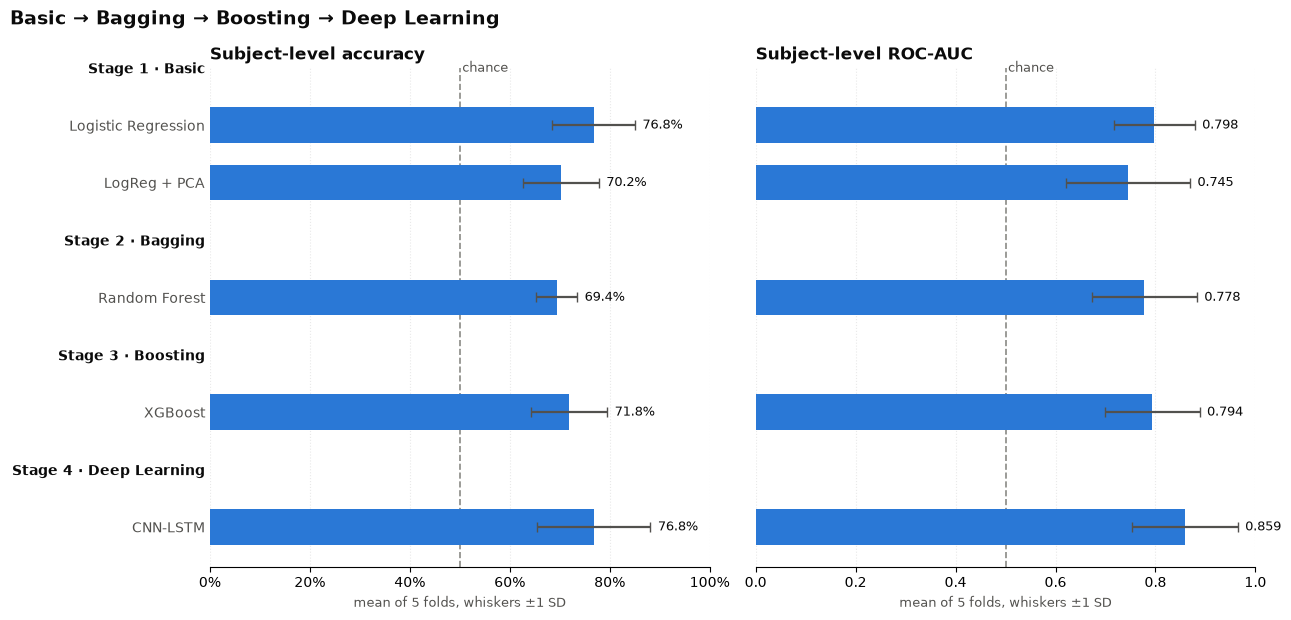

In [3]:
rows = []
for st in sorted(res.stage.unique()):
    rows.append(("header", st, None))
    for _, r in res[res.stage == st].iterrows():
        rows.append(("model", r.model, r))
ypos = np.arange(len(rows))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 0.52 * len(rows) + 1.6), sharey=True)
for ax, (col, title) in zip(axes, [("subject_acc", "Subject-level accuracy"), ("subject_auc", "Subject-level ROC-AUC")]):
    for yv, (kind, name, r) in zip(ypos, rows):
        if kind != "model": continue
        m, s = r[col], r[col + "_sd"]
        ax.barh(yv, m, height=.62, color=BLUE, zorder=3)
        ax.errorbar(m, yv, xerr=s, fmt="none", ecolor=MUTED, elinewidth=1.6, capsize=3.5, zorder=4)
        ax.text(min(m + s + .015, .985), yv, ("%.1f%%" % (100 * m)) if col == "subject_acc" else "%.3f" % m,
                va="center", fontsize=9.5, color=INK, zorder=5)
    ax.axvline(.5, ls="--", lw=1.2, color=GRID, zorder=2)
    ax.text(.505, ypos[0], "chance", color=MUTED, fontsize=9, va="center")
    ax.set_xlim(0, 1.0)
    if col == "subject_acc": ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title, fontsize=12, weight="bold", loc="left", color=INK)
    ax.set_xlabel("mean of 5 folds, whiskers \u00b11 SD", fontsize=9.5, color=MUTED)
    ax.grid(axis="x", alpha=.28, ls=":", zorder=0); ax.grid(axis="y", visible=False)
    for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)

labels = [("Stage " + n.replace(" - ", " \u00b7 ")) if k == "header" else ("    " + n) for k, n, _ in rows]
axes[0].set_yticks(ypos, labels, fontsize=10)
for tick, (k, _, _) in zip(axes[0].get_yticklabels(), rows):
    tick.set_fontweight("bold" if k == "header" else "normal"); tick.set_color(INK if k == "header" else MUTED)
fig.suptitle("Basic \u2192 Bagging \u2192 Boosting \u2192 Deep Learning", x=.01, ha="left", fontsize=14, weight="bold", color=INK)
plt.tight_layout()
os.makedirs("figures", exist_ok=True); plt.savefig("figures/model_progression.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 3 - Fold by fold

**What this does.** Shows every model's subject-AUC on each fold. Because all
models share the same folds, each column is the *same ~24 test subjects*.

**How to read it.** If one column is low for every model, that fold's subjects
are hard - the variation is coming from the people, not the models. A model
that beats the baseline on most columns is more convincing than one with a
higher mean driven by a single fold.

In [4]:
piv = folds.pivot(index="model", columns="fold", values="subject_auc").reindex(res.model)
piv.columns = ["fold %d" % c for c in piv.columns]
display(piv.round(3).style.background_gradient(cmap="Blues", axis=None, vmin=.5, vmax=1.0).format("{:.3f}"))

hardest = piv.idxmin(axis=1)
print("hardest fold for each model:", hardest.to_dict())
print("-> %d of %d models found the same fold hardest." % (hardest.value_counts().max(), len(hardest)))

,fold 0,fold 1,fold 2,fold 3,fold 4
model,,,,,
Logistic Regression,0.819,0.847,0.891,0.694,0.736
LogReg + PCA,0.743,0.875,0.859,0.590,0.660
Random Forest,0.854,0.868,0.840,0.660,0.667
XGBoost,0.861,0.854,0.872,0.701,0.681
CNN-LSTM,0.840,0.826,0.962,0.708,0.958


hardest fold for each model: {'Logistic Regression': 'fold 3', 'LogReg + PCA': 'fold 3', 'Random Forest': 'fold 3', 'XGBoost': 'fold 4', 'CNN-LSTM': 'fold 3'}
-> 4 of 5 models found the same fold hardest.


## Step 4 - Each stage against the baseline

**What this does.** Compares every model with Stage 1 logistic regression on
the same folds: how many folds it won, the mean AUC difference, and a paired
t-test across the five folds.

**How to read it.** "Within noise" means the mean difference is smaller than
the fold-to-fold spread. With only five folds the t-test has little power, so
a non-significant result says "not demonstrated", not "no difference".

In [5]:
base = piv.loc["Logistic Regression"]
print("%-20s %-10s %-9s %-9s %s" % ("model", "folds won", "mean dAUC", "p (t)", "verdict"))
for m in piv.index:
    if m == "Logistic Regression": continue
    d = piv.loc[m] - base
    t, p = stats.ttest_rel(piv.loc[m], base)
    noise = max(res.set_index("model").subject_auc_sd[[m, "Logistic Regression"]])
    verdict = ("clearly better" if d.mean() > noise else "clearly worse" if d.mean() < -noise else "within noise")
    print("%-20s %d / %d      %+.3f     %.3f     %s" % (m, (d > 0).sum(), len(d), d.mean(), p, verdict))

best = res.loc[res.subject_auc.idxmax()]
within = res[res.subject_auc >= best.subject_auc - best.subject_auc_sd]
print("\nBest subject-AUC: %s (%.3f +- %.3f)" % (best.model, best.subject_auc, best.subject_auc_sd))
print("Within one SD of it (not separable on this data):", ", ".join(within.model))

model                folds won  mean dAUC p (t)     verdict
LogReg + PCA         1 / 5      -0.052     0.087     within noise
Random Forest        2 / 5      -0.020     0.382     within noise
XGBoost              3 / 5      -0.004     0.823     within noise
CNN-LSTM             4 / 5      +0.061     0.225     within noise

Best subject-AUC: CNN-LSTM (0.859 +- 0.105)
Within one SD of it (not separable on this data): Logistic Regression, Random Forest, XGBoost, CNN-LSTM


## Reporting this honestly

- **Quote subject-level numbers with their +- SD.** The spread between folds
  is large on 121 subjects, and a bare mean hides it.
- **"Within noise" is a result, not a failure.** If a more complex stage does
  not beat the baseline by more than one standard deviation, the honest
  conclusion is that the extra complexity was not justified on this dataset -
  and the simpler model is the one to recommend.
- **The protocol mattered more than the model.** Filtering, epoching,
  subject-grouped folds and per-subject decisions are what make these numbers
  mean something. Scoring individual 7.8 ms samples on a row-wise split would
  have put the same logistic regression at chance.